### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf, plot_predict

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global variables

In [7]:
obv_st_date = pd.to_datetime("2021-07-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2021-07-01")
pred_end_date = pd.to_datetime("2022-01-01")

### Loading and Cleaning data

In [8]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [9]:
data.shape

(31972, 14)

In [10]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preparing for Prediction

In [11]:
DMFM_Y = data.copy()
mask = (DMFM_Y['category']=='miscellaneous food') & (DMFM_Y['region']=='Yangon')
DMFM_Y = DMFM_Y.loc[mask]
DMFM_Y.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
27756,7/15/2021,Yangon,Yangon (East),Ngazalgwae,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,410.00,0.2303
27761,7/15/2021,Yangon,Yangon (East),Zamyinzwel,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,350.00,0.1966
27767,7/15/2021,Yangon,Yangon (North),Meegwet,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,245.00,0.1376
27774,7/15/2021,Yangon,Yangon (North),YwarMa,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,245.00,0.1376
28899,9/15/2021,Yangon,Yangon (East),Ngazalgwae,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,403.92,0.2269


In [12]:
DMFM_Y = DMFM_Y[['date', 'price']]
DMFM_Y['date'] = pd.to_datetime(DMFM_Y['date'])
mask = (DMFM_Y['date']>=obv_st_date) & (DMFM_Y['date']<=obv_end_date)
DMFM_Y = DMFM_Y.loc[mask]
DMFM_Y = DMFM_Y.set_index('date')
DMFM_Y.head()

,price
date,
2021-07-15,410.00
2021-07-15,350.00
2021-07-15,245.00
2021-07-15,245.00
2021-09-15,403.92


In [13]:
DMFM_Y = DMFM_Y.resample('MS').mean()
DMFM_Y.head()

,price
date,
2021-07-01,312.500
2021-08-01,NaN
2021-09-01,329.460
2021-10-01,303.000
2021-11-01,298.248


In [14]:
DMFM_Y = DMFM_Y.bfill()

In [15]:
DMFM_Y.shape

(7, 1)

There are only 6 records. We have not enough record for prediction. However let test it.

### According to this dataframe, we need to reset again datatime

In [16]:
obv_st_date = pd.to_datetime("2021-07-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2021-07-01")
pred_end_date = pd.to_datetime("2022-09-01")

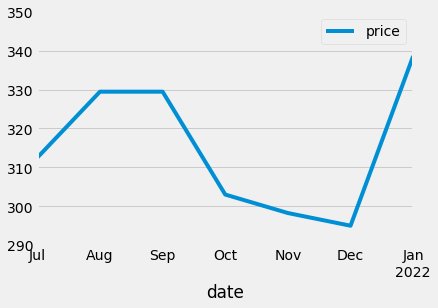

In [17]:
DMFM_Y.plot(grid=True)
plt.show()

It has no trend

##### Checking Random Walk

In [18]:
RW_DMFM_Y= adfuller(DMFM_Y)
RW_DMFM_Y[1] # print P-value. If p-value<5%, reject null hypothesis

0.30610778497777025

<span style="color:red">Are there any external factors that may influence this price?</span>

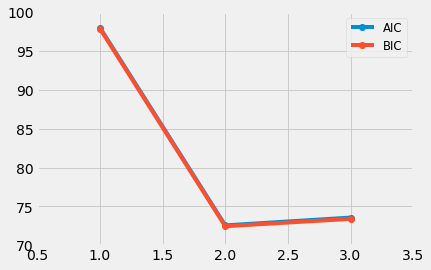

In [19]:
AIC, BIC = AIC_BIC_withOrderRange(DMFM_Y, p=2, q=2)
# 0:(0,0,0), 1:(0,0,1), 2:(1,0,0), 3:(1,0,1)

In [20]:
AIC, BIC

(array([102.42726461,  97.97951156,  72.56277589,  73.56241112]),
 array([102.37317475,  97.87133185,  72.45459618,  73.40014157]))

We will run again 2:(1,0,0), 3:(1,0,1)

In [21]:
mod_orders = [
    (1,0,0),
    (1,0,1)
]

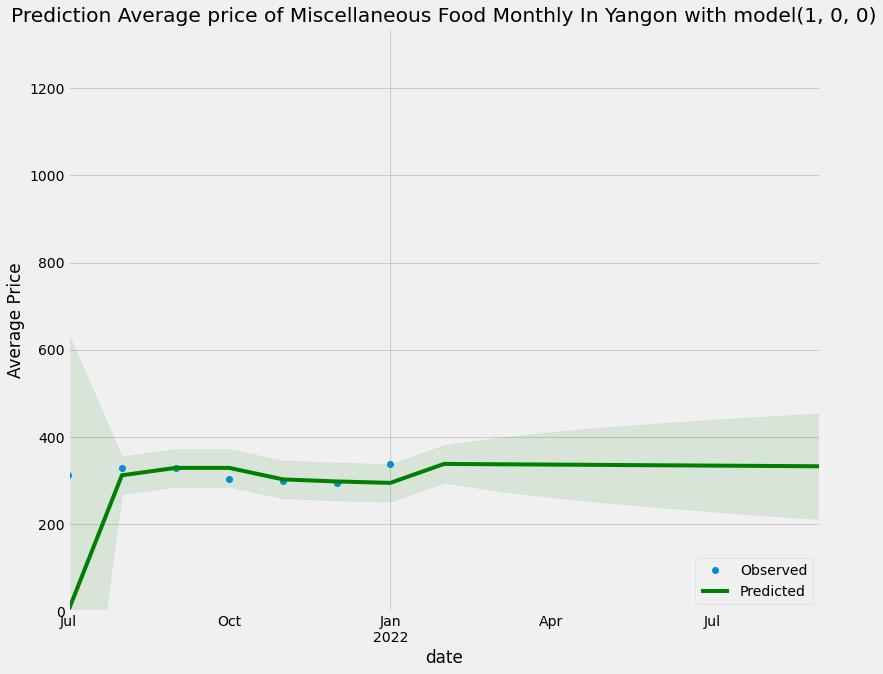

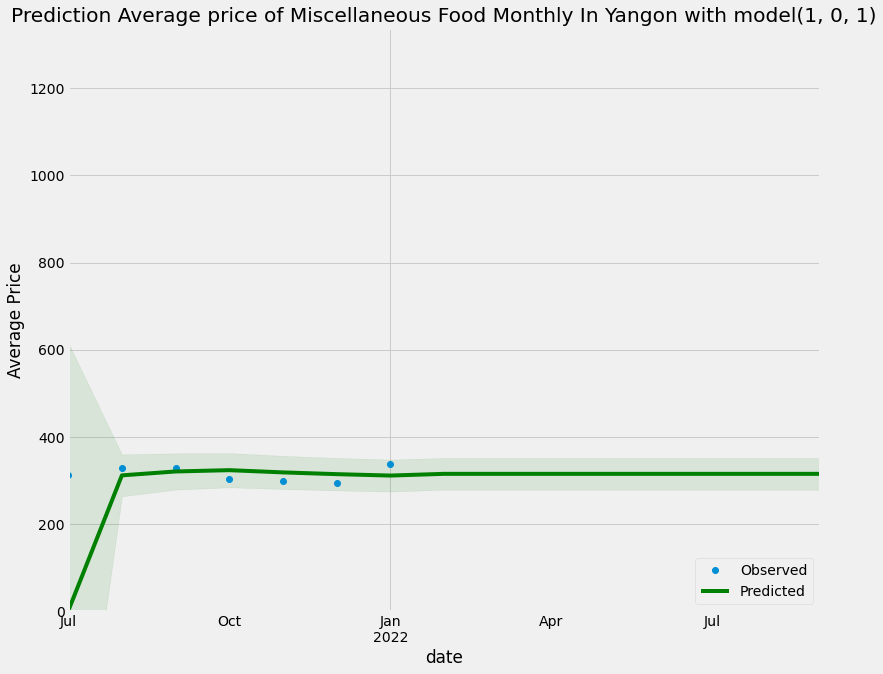

In [22]:
DMFM_Y_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DMFM_Y, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Miscellaneous Food Monthly In Yangon with model'+str(order), xlabel='Date', ylabel='Average Price')
    DMFM_Y_models.append(model)

Now we choose (1,0,0)

In [23]:
DMFM_Y_model = DMFM_Y_models[0]

In [24]:
DMFM_Y_pred = DMFM_Y_model.predict(pred_st_date, pred_end_date)
DMFM_Y_pred

2021-07-01      0.000000
2021-08-01    311.781791
2021-09-01    328.702812
2021-10-01    328.702812
2021-11-01    302.303624
2021-12-01    297.562546
2022-01-01    294.306047
2022-02-01    337.821806
2022-03-01    337.045400
2022-04-01    336.270779
2022-05-01    335.497938
2022-06-01    334.726873
2022-07-01    333.957581
2022-08-01    333.190056
2022-09-01    332.424296
Freq: MS, Name: predicted_mean, dtype: float64